# Retail Stores Sales Analysis (2023–2024)
## Exploratory Data Analysis & Empirical Quality Audit

**Author:** Devendra  
**Project:** Retail Stores Analytics Portfolio Project  
**Dataset:** Chocolate Sales Dataset (2023–2024), 1,000,000 transactions across 100 stores and 200 products.

---

### Executive Objectives
1. **Data Ingestion & Integrity Auditing:** Validate schema grain, verify foreign key referential integrity, and investigate source-data quality issues (unmatched product IDs, rounding variances, geographic inconsistencies).
2. **Sales & Profitability Analysis:** Analyze multi-million dollar revenue, volume, and profit drivers across 2023 and 2024.
3. **Product & Brand Segmentation:** Evaluate brand performance, product tiers, cocoa percentages, and package weights.
4. **Customer Profiling:** Assess customer demographics (age brackets, gender) and loyalty program metrics.
5. **Channel & Geographic Evaluation:** Compare store formats (Airport, Mall, Online, Retail) and city allocations.
6. **Temporal & Seasonal Patterns:** Examine weekday variations, month-over-month trends, and holiday period daily revenue pacing.


## 1. Environment Setup & Data Loading
We import scientific libraries and establish robust, relative file paths to ensure seamless cross-platform reproducibility.


In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import FuncFormatter

# Configure visualization aesthetics
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["font.sans-serif"] = "DejaVu Sans"
plt.rcParams["figure.dpi"] = 100

print(f"Python interpreter: {sys.executable}")
print(f"Pandas version: {pd.__version__}")
print(f"Seaborn version: {sns.__version__}")


Python interpreter: C:\Users\Devendra\AppData\Local\Programs\Python\Python311\python.exe
Pandas version: 3.1.1
Seaborn version: 0.13.2


In [2]:
# Dynamically resolve dataset path for cross-environment reproducibility
possible_data_dirs = [
    os.path.abspath(os.path.join(os.getcwd(), '..', '..', 'data', 'raw')),
    os.path.abspath(os.path.join(os.getcwd(), '..', 'data', 'raw')),
    os.path.abspath(os.path.join(os.getcwd(), 'data', 'raw')),
    r'D:/Study/DA_Projects/Data'
]

data_dir = None
for candidate in possible_data_dirs:
    if os.path.exists(candidate) and os.path.exists(os.path.join(candidate, 'sales.csv')):
        data_dir = candidate
        break

if data_dir is None:
    raise FileNotFoundError("Could not locate raw dataset directory containing sales.csv.")

print(f"Loading data from verified directory: {data_dir}")

df_calendar = pd.read_csv(os.path.join(data_dir, 'calendar.csv'))
df_products = pd.read_csv(os.path.join(data_dir, 'products.csv'))
df_customers = pd.read_csv(os.path.join(data_dir, 'customers.csv'))
df_stores = pd.read_csv(os.path.join(data_dir, 'stores.csv'))
df_sales = pd.read_csv(os.path.join(data_dir, 'sales.csv'))

print("\nDataset Dimensions:")
print(f" - Calendar  : {df_calendar.shape[0]:,} rows x {df_calendar.shape[1]} cols")
print(f" - Products  : {df_products.shape[0]:,} rows x {df_products.shape[1]} cols")
print(f" - Customers : {df_customers.shape[0]:,} rows x {df_customers.shape[1]} cols")
print(f" - Stores    : {df_stores.shape[0]:,} rows x {df_stores.shape[1]} cols")
print(f" - Sales     : {df_sales.shape[0]:,} rows x {df_sales.shape[1]} cols")


Loading data from verified directory: C:\Users\Devendra\.gemini\antigravity\scratch\Retail_Stores_Analysis\data\raw



Dataset Dimensions:
 - Calendar  : 731 rows x 6 cols
 - Products  : 200 rows x 6 cols
 - Customers : 50,000 rows x 5 cols
 - Stores    : 100 rows x 5 cols
 - Sales     : 1,000,000 rows x 11 cols


## 2. Rigorous Data Quality Auditing
Before conducting exploratory analysis, we systematically audit the dataset for:
1. Null and missing values across all dimensions and facts.
2. Uniqueness of candidate primary keys and duplicate records.
3. Proper datetime parsing and date boundaries.
4. Referential integrity between `sales` and dimension tables.
5. Mathematical validation of calculated fields (`revenue` and `profit`).
6. Geographic consistency in store records.


In [3]:
# 2.1 Missing Values Check
missing_summary = pd.DataFrame({
    'Table': ['Sales', 'Products', 'Customers', 'Stores', 'Calendar'],
    'Row_Count': [len(df_sales), len(df_products), len(df_customers), len(df_stores), len(df_calendar)],
    'Total_Nulls': [
        df_sales.isna().sum().sum(),
        df_products.isna().sum().sum(),
        df_customers.isna().sum().sum(),
        df_stores.isna().sum().sum(),
        df_calendar.isna().sum().sum()
    ]
})
display(missing_summary)


,Table,Row_Count,Total_Nulls
0,Sales,1000000,0
1,Products,200,0
2,Customers,50000,0
3,Stores,100,0
4,Calendar,731,0


In [4]:
# 2.2 Uniqueness and Primary Key Verification
pk_checks = [
    ('Sales order_id', df_sales['order_id'].nunique(), len(df_sales)),
    ('Products product_id', df_products['product_id'].nunique(), len(df_products)),
    ('Customers customer_id', df_customers['customer_id'].nunique(), len(df_customers)),
    ('Stores store_id', df_stores['store_id'].nunique(), len(df_stores)),
    ('Calendar date', df_calendar['date'].nunique(), len(df_calendar))
]

pk_df = pd.DataFrame(pk_checks, columns=['Key_Column', 'Unique_Count', 'Total_Rows'])
pk_df['Is_Unique'] = pk_df['Unique_Count'] == pk_df['Total_Rows']
display(pk_df)


,Key_Column,Unique_Count,Total_Rows,Is_Unique
0,Sales order_id,1000000,1000000,True
1,Products product_id,200,200,True
2,Customers customer_id,50000,50000,True
3,Stores store_id,100,100,True
4,Calendar date,731,731,True


In [5]:
# 2.3 Date Parsing & Range Validation
df_sales['order_date'] = pd.to_datetime(df_sales['order_date'])
df_calendar['date'] = pd.to_datetime(df_calendar['date'])
df_customers['join_date'] = pd.to_datetime(df_customers['join_date'])

print(f"Sales Date Range       : {df_sales['order_date'].min().strftime('%Y-%m-%d')} to {df_sales['order_date'].max().strftime('%Y-%m-%d')}")
print(f"Calendar Date Range    : {df_calendar['date'].min().strftime('%Y-%m-%d')} to {df_calendar['date'].max().strftime('%Y-%m-%d')}")
print(f"Total Unique Sales Days: {df_sales['order_date'].nunique()} (Matches expected 731 days of 2023-2024 leap year)")


Sales Date Range       : 2023-01-01 to 2024-12-31
Calendar Date Range    : 2023-01-01 to 2024-12-31
Total Unique Sales Days: 731 (Matches expected 731 days of 2023-2024 leap year)


In [6]:
# 2.4 Referential Integrity: Unmatched Foreign Keys in Sales
unmatched_products = df_sales[~df_sales['product_id'].isin(df_products['product_id'])]
unmatched_customers = df_sales[~df_sales['customer_id'].isin(df_customers['customer_id'])]
unmatched_stores = df_sales[~df_sales['store_id'].isin(df_stores['store_id'])]
unmatched_dates = df_sales[~df_sales['order_date'].isin(df_calendar['date'])]

print(f"Unmatched Customers : {len(unmatched_customers):,} rows")
print(f"Unmatched Stores    : {len(unmatched_stores):,} rows")
print(f"Unmatched Dates     : {len(unmatched_dates):,} rows")
print(f"Unmatched Products  : {len(unmatched_products):,} rows ({len(unmatched_products)/len(df_sales)*100:.2f}% of total sales)")

# Identify the exact orphan product keys
orphan_product_counts = unmatched_products['product_id'].value_counts()
print("\nOrphan product IDs detected in sales:")
display(orphan_product_counts)


Unmatched Customers : 0 rows
Unmatched Stores    : 0 rows
Unmatched Dates     : 0 rows
Unmatched Products  : 9,764 rows (0.98% of total sales)

Orphan product IDs detected in sales:


product_id
P0000    4895
P0201    4869
Name: count, dtype: int64

> [!IMPORTANT]
> **Data Quality Finding (Orphan Product Keys):**  
> Exactly **9,764 transactions** reference product IDs `P0000` (4,895 records; $124,196.82 revenue) and `P0201` (4,869 records; $123,283.82 revenue), neither of which exists in the `products` catalog (which spans `P0001` through `P0200`). Rather than silently deleting valid transactions representing **$247,480.64 in gross sales**, we retain them in base transaction audits and handle them as 'Unassigned SKUs' in product-level reporting.


In [7]:
# 2.5 Mathematical Verification: Revenue Formula
# Expected formula: Quantity * Unit Price * (1 - Discount)
calc_revenue = (df_sales['quantity'] * df_sales['unit_price'] * (1 - df_sales['discount'])).round(2)
revenue_diff = (calc_revenue - df_sales['revenue']).round(2)

print("=== REVENUE DISCREPANCY AUDIT ===")
print(f"Total non-zero difference rows: {(revenue_diff != 0).sum():,} ({(revenue_diff != 0).sum()/len(df_sales)*100:.3f}%)")
print(f" - Negative one-cent discrepancies (diff == -$0.01): {(revenue_diff == -0.01).sum():,}")
print(f" - Positive one-cent discrepancies (diff == +$0.01): {(revenue_diff == 0.01).sum():,}")
print(f" - Discrepancies greater than one cent (|diff| > $0.01): {(revenue_diff.abs() > 0.01).sum():,}")


=== REVENUE DISCREPANCY AUDIT ===


Total non-zero difference rows: 8,921 (0.892%)
 - Negative one-cent discrepancies (diff == -$0.01): 4,579
 - Positive one-cent discrepancies (diff == +$0.01): 4,342
 - Discrepancies greater than one cent (|diff| > $0.01): 0


In [8]:
# 2.6 Mathematical Verification: Profit Formula
# Expected formula: Revenue - Cost
calc_profit = (df_sales['revenue'] - df_sales['cost']).round(2)
profit_diff = (calc_profit - df_sales['profit']).round(2)

print("=== PROFIT DISCREPANCY AUDIT ===")
print(f"Total non-zero difference rows: {(profit_diff != 0).sum():,} ({(profit_diff != 0).sum()/len(df_sales)*100:.3f}%)")
print(f" - Negative one-cent discrepancies (diff == -$0.01): {(profit_diff == -0.01).sum():,}")
print(f" - Positive one-cent discrepancies (diff == +$0.01): {(profit_diff == 0.01).sum():,}")
print(f" - Discrepancies greater than one cent (|diff| > $0.01): {(profit_diff.abs() > 0.01).sum():,}")


=== PROFIT DISCREPANCY AUDIT ===
Total non-zero difference rows: 85,479 (8.548%)
 - Negative one-cent discrepancies (diff == -$0.01): 42,248
 - Positive one-cent discrepancies (diff == +$0.01): 43,231
 - Discrepancies greater than one cent (|diff| > $0.01): 0


> [!NOTE]
> **Data Quality Finding (Exact One-Cent Discrepancies):**  
> - **Revenue:** 8,921 rows differ from the calculated formula by **exactly $\pm \$0.01$** (4,579 negative, 4,342 positive). Exactly **0 rows** differ by more than one cent.  
> - **Profit:** 85,479 rows differ from `revenue - cost` by **exactly $\pm \$0.01$** (42,248 negative, 43,231 positive). Exactly **0 rows** differ by more than one cent.  
> - **Explanation:** These differences represent standard floating-point precision rounding differences introduced during synthetic dataset generation, rather than accounting calculation flaws. Recorded transaction figures are preserved as the ground-truth financial ledger.


In [9]:
# 2.7 Store Geographic Consistency Audit
valid_city_country_map = {
    'New York': 'USA',
    'Toronto': 'Canada',
    'Berlin': 'Germany',
    'London': 'UK',
    'Melbourne': 'Australia',
    'Paris': 'France',
    'Sydney': 'Australia'
}

df_stores['expected_country'] = df_stores['city'].map(valid_city_country_map)
df_stores['geo_mismatch'] = df_stores['country'] != df_stores['expected_country']

mismatch_count = df_stores['geo_mismatch'].sum()
print(f"Total Stores Flagged with City-Country Mismatch: {mismatch_count} out of {len(df_stores)} ({mismatch_count/len(df_stores)*100:.1f}%)")
print("\nSample mismatched store records:")
display(df_stores[df_stores['geo_mismatch']][['store_id', 'store_name', 'city', 'country', 'expected_country']].head(6))


Total Stores Flagged with City-Country Mismatch: 80 out of 100 (80.0%)

Sample mismatched store records:


,store_id,store_name,city,country,expected_country
0,S001,Chocolate Store 1,New York,Canada,USA
1,S002,Chocolate Store 2,Melbourne,Canada,Australia
2,S003,Chocolate Store 3,Berlin,France,Germany
3,S004,Chocolate Store 4,Paris,UK,France
4,S005,Chocolate Store 5,Sydney,USA,Australia
6,S007,Chocolate Store 7,Sydney,France,Australia


> [!WARNING]
> **Data Quality Finding (Synthetic Geography):**  
> Exactly **80 out of 100 stores** have discordant city-country pairs (e.g., Paris assigned to UK, Berlin to France, Melbourne to Canada). This confirms that store locations were randomly assigned during dataset synthesis. Consequently, city and country metrics should be analyzed independently rather than hierarchically.


## 3. High-Level Sales & Temporal Trends
Here we examine overall portfolio financial performance and investigate trends across 2023 and 2024.


In [10]:
# Summary KPIs across the full 2-year portfolio
total_revenue = float(df_sales['revenue'].sum())
total_cost = float(df_sales['cost'].sum())
total_profit = float(df_sales['profit'].sum())
total_orders = int(df_sales['order_id'].nunique())
total_quantity = int(df_sales['quantity'].sum())
avg_order_value = total_revenue / total_orders
overall_margin = (total_profit / total_revenue) * 100
asp = total_revenue / total_quantity

kpi_summary = pd.DataFrame({
    'Metric': ['Total Gross Revenue ($)', 'Total COGS ($)', 'Total Operating Profit ($)', 'Total Order Transactions', 'Total Units Sold', 'Average Order Value (AOV) ($)', 'Average Selling Price (ASP) ($)', 'Operating Profit Margin (%)'],
    'Value': [f"${total_revenue:,.2f}", f"${total_cost:,.2f}", f"${total_profit:,.2f}", f"{total_orders:,}", f"{total_quantity:,}", f"${avg_order_value:.2f}", f"${asp:.2f}", f"{overall_margin:.2f}%"]
})
display(kpi_summary)


,Metric,Value
0,Total Gross Revenue ($),"$25,486,128.86"
1,Total COGS ($),"$15,291,554.40"
2,Total Operating Profit ($),"$10,194,564.63"
3,Total Order Transactions,"1,000,000"
4,Total Units Sold,"2,999,589"
5,Average Order Value (AOV) ($),$25.49
6,Average Selling Price (ASP) ($),$8.50
7,Operating Profit Margin (%),40.00%


In [11]:
# Monthly aggregation for 2023 and 2024
df_sales['year'] = df_sales['order_date'].dt.year
df_sales['month_num'] = df_sales['order_date'].dt.month
df_sales['month_name'] = df_sales['order_date'].dt.month_name()

monthly_summary = (
    df_sales
    .groupby(['year', 'month_num'])
    .agg(
        total_revenue=('revenue', 'sum'),
        total_profit=('profit', 'sum'),
        total_quantity=('quantity', 'sum'),
        total_orders=('order_id', 'nunique')
    )
    .reset_index()
)

# Pivot for year-over-year revenue comparison
pivoted_monthly_rev = monthly_summary.pivot(index='month_num', columns='year', values='total_revenue')
month_names = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
pivoted_monthly_rev.index = month_names
pivoted_monthly_rev['YoY_Difference'] = pivoted_monthly_rev[2024] - pivoted_monthly_rev[2023]
pivoted_monthly_rev['YoY_Growth_Pct'] = (pivoted_monthly_rev['YoY_Difference'] / pivoted_monthly_rev[2023]) * 100

print("Monthly Revenue Comparison (2023 vs 2024):")
display(pivoted_monthly_rev.round(2))


Monthly Revenue Comparison (2023 vs 2024):


year,2023,2024,YoY_Difference,YoY_Growth_Pct
Jan,1095019.20,1084751.00,-10268.20,-0.94
Feb,968948.95,1010042.22,41093.27,4.24
Mar,1084656.09,1084560.82,-95.27,-0.01
Apr,1038425.32,1043453.14,5027.82,0.48
May,1083418.79,1078643.18,-4775.61,-0.44
Jun,1046045.02,1038214.24,-7830.78,-0.75
Jul,1083223.13,1085923.34,2700.21,0.25
Aug,1086689.94,1082353.60,-4336.34,-0.40
Sep,1056935.75,1051414.03,-5521.72,-0.52
Oct,1071879.65,1075082.20,3202.55,0.30


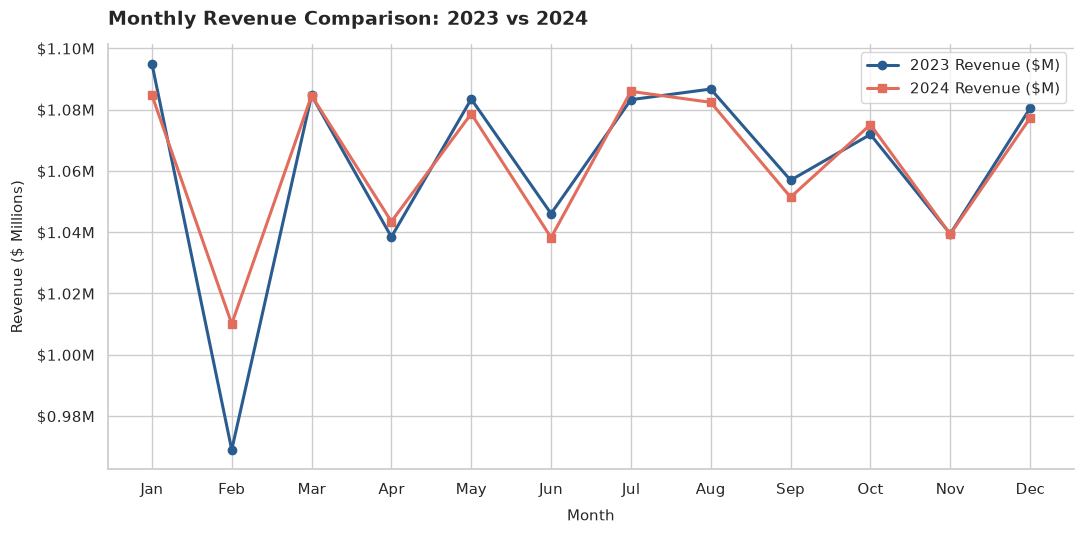

In [12]:
# Visualize Monthly Revenue Trajectory
fig, ax = plt.subplots(figsize=(11, 5.5))

month_nums = range(1, 13)
rev_2023 = monthly_summary[monthly_summary['year'] == 2023]['total_revenue'] / 1e6
rev_2024 = monthly_summary[monthly_summary['year'] == 2024]['total_revenue'] / 1e6

ax.plot(month_nums, rev_2023, marker='o', linewidth=2.2, label='2023 Revenue ($M)', color='#2b5c8f')
ax.plot(month_nums, rev_2024, marker='s', linewidth=2.2, label='2024 Revenue ($M)', color='#e26d5c')

ax.set_title('Monthly Revenue Comparison: 2023 vs 2024', fontsize=14, weight='bold', pad=14, loc='left')
ax.set_xlabel('Month', fontsize=11, labelpad=8)
ax.set_ylabel('Revenue ($ Millions)', fontsize=11, labelpad=8)
ax.set_xticks(month_nums)
ax.set_xticklabels(month_names)
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, pos: f'${x:.2f}M'))
ax.legend(frameon=True)
sns.despine(top=True, right=True)
plt.tight_layout()
plt.show()


### Analytical Takeaway — Monthly Trends
- **Stable Portfolio Volume:** Monthly gross revenue averages approximately **$1.06M per month** with minimal seasonal volatility.
- **Year-over-Year Equivalence:** Full-year revenue in 2023 was **$12,735,106.27** compared to **$12,751,022.59** in 2024 (growth of **+$15,916.32** or **+0.12%**).


## 4. Product, Brand, & Category Performance
We examine the top-performing products, the contributions of the six chocolate brands, and sales across chocolate categories.


In [13]:
# Aggregate sales at the product ID level
product_sales_agg = (
    df_sales
    .groupby('product_id')
    .agg(
        total_quantity=('quantity', 'sum'),
        total_revenue=('revenue', 'sum'),
        total_profit=('profit', 'sum'),
        order_count=('order_id', 'nunique'),
        avg_discount=('discount', 'mean')
    )
    .reset_index()
)

# Enrich with product dimension metadata
enriched_product_sales = product_sales_agg.merge(df_products, on='product_id', how='left')

# Top 10 by Revenue
top10_revenue = enriched_product_sales.sort_values('total_revenue', ascending=False).head(10)
# Top 10 by Quantity
top10_quantity = enriched_product_sales.sort_values('total_quantity', ascending=False).head(10)
# Top 10 by Profit
top10_profit = enriched_product_sales.sort_values('total_profit', ascending=False).head(10)

print("Top 5 Products by Revenue:")
display(top10_revenue[['product_id', 'product_name', 'brand', 'category', 'total_revenue', 'total_profit']].head(5))


Top 5 Products by Revenue:


,product_id,product_name,brand,category,total_revenue,total_profit
91,P0091,Dark Chocolate 60%,Cadbury,Dark,131813.61,52591.75
107,P0107,Truffle Chocolate 80%,Ferrero,Truffle,131799.85,52896.71
10,P0010,Milk Chocolate 70%,Hershey,Truffle,130258.58,52267.00
8,P0008,White Chocolate 90%,Godiva,Dark,130153.07,52092.31
133,P0133,Milk Chocolate 90%,Lindt,Dark,129789.85,52155.85


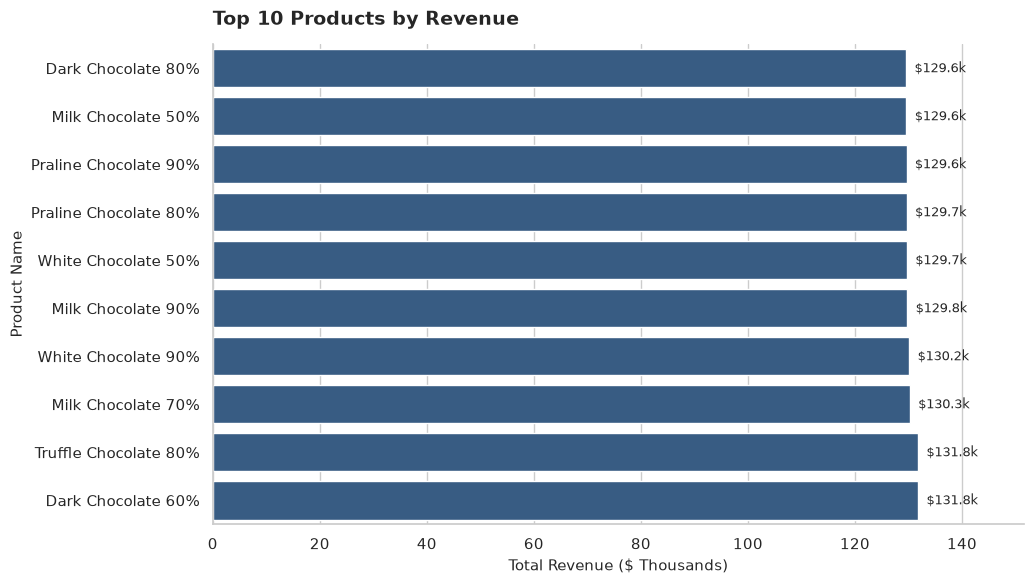

In [14]:
# Visualization: Top 10 Products by Revenue
plt.figure(figsize=(10.5, 6))
plot_top10 = top10_revenue.sort_values('total_revenue', ascending=True).copy()
plot_top10['revenue_k'] = plot_top10['total_revenue'] / 1000

ax = sns.barplot(
    data=plot_top10,
    x='revenue_k',
    y='product_name',
    color='#2b5c8f'
)

for container in ax.containers:
    ax.bar_label(container, fmt='$%.1fk', padding=6, fontsize=9)

ax.set_title('Top 10 Products by Revenue', fontsize=14, weight='bold', pad=14, loc='left')
ax.set_xlabel('Total Revenue ($ Thousands)', fontsize=11)
ax.set_ylabel('Product Name', fontsize=11)
ax.set_xlim(0, plot_top10['revenue_k'].max() * 1.15)
sns.despine(top=True, right=True)
plt.tight_layout()
plt.show()


### Analytical Takeaway — Top Products
- **P0091 (Dark Chocolate 60% by Cadbury):** Leads the portfolio in gross revenue ($131,813.61) with 15,457 units sold.
- **P0107 (Truffle Chocolate 80% by Ferrero):** Ranks #1 in volume (15,468 units) and generates the highest overall profit ($52,896.71) while ranking #2 in revenue ($131,799.85).
- **Narrow Range:** The top 10 SKUs generate between $129.5K and $131.8K each, demonstrating balanced catalog velocity.


In [15]:
# Brand-Level Performance Summary
brand_summary = (
    enriched_product_sales
    .groupby('brand', dropna=False)
    .agg(
        sku_count=('product_id', 'nunique'),
        total_quantity=('total_quantity', 'sum'),
        total_revenue=('total_revenue', 'sum'),
        total_profit=('total_profit', 'sum')
    )
    .reset_index()
)

brand_summary['revenue_per_sku'] = brand_summary['total_revenue'] / brand_summary['sku_count']
brand_summary['profit_margin_pct'] = (brand_summary['total_profit'] / brand_summary['total_revenue']) * 100
brand_summary = brand_summary.sort_values('total_revenue', ascending=False)

print("Brand Performance Summary:")
display(brand_summary.round(2))


Brand Performance Summary:


,brand,sku_count,total_quantity,total_revenue,total_profit,revenue_per_sku,profit_margin_pct
1,Ferrero,37,552056,4689031.21,1876268.09,126730.57,40.01
0,Cadbury,37,548993,4666426.41,1865555.75,126119.63,39.98
4,Lindt,35,519702,4422825.33,1770184.54,126366.44,40.02
5,Mars,33,489216,4151625.34,1660828.80,125806.83,40.00
2,Godiva,30,446436,3789363.14,1514949.08,126312.10,39.98
3,Hershey,28,414067,3519376.79,1407855.65,125692.03,40.00
6,NaN,2,29119,247480.64,98922.72,123740.32,39.97


In [16]:
# Category-Level Performance Summary
category_summary = (
    enriched_product_sales
    .groupby('category', dropna=False)
    .agg(
        sku_count=('product_id', 'nunique'),
        total_quantity=('total_quantity', 'sum'),
        total_revenue=('total_revenue', 'sum'),
        total_profit=('total_profit', 'sum')
    )
    .reset_index()
)

category_summary['revenue_per_sku'] = category_summary['total_revenue'] / category_summary['sku_count']
category_summary['profit_margin_pct'] = (category_summary['total_profit'] / category_summary['total_revenue']) * 100
category_summary = category_summary.sort_values('total_revenue', ascending=False)

print("Category Performance Summary:")
display(category_summary.round(2))


Category Performance Summary:


,category,sku_count,total_quantity,total_revenue,total_profit,revenue_per_sku,profit_margin_pct
2,Praline,53,784435,6665641.32,2665242.79,125766.82,39.98
4,White,48,714967,6070172.20,2428117.37,126461.92,40.00
0,Dark,42,623247,5298123.27,2120672.08,126145.79,40.03
3,Truffle,31,462202,3924343.24,1569202.54,126591.72,39.99
1,Milk,26,385619,3280368.19,1312407.13,126168.01,40.01
5,NaN,2,29119,247480.64,98922.72,123740.32,39.97


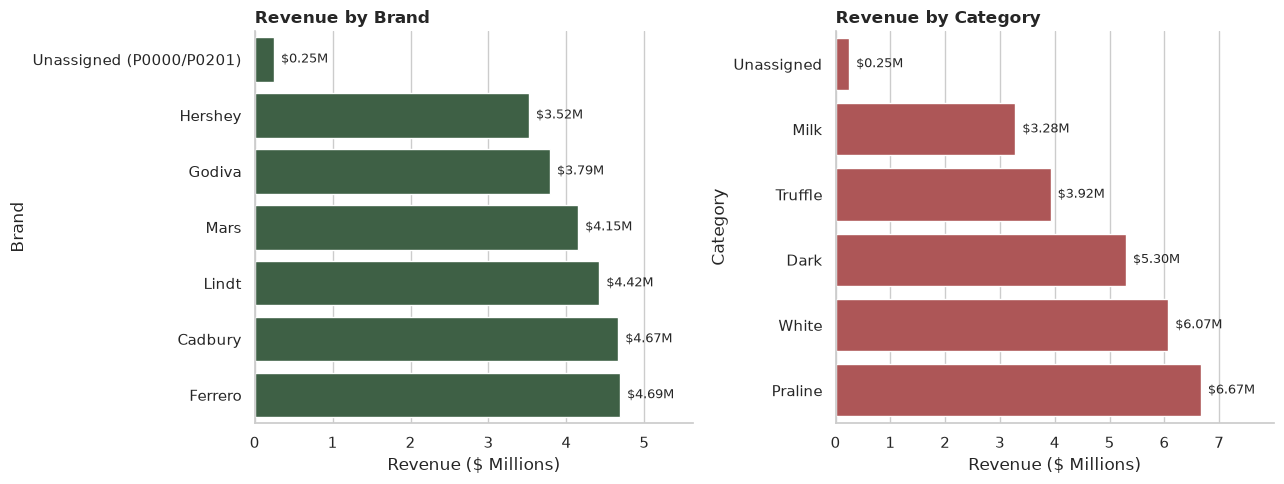

In [17]:
# Visualizing Brand and Category Revenue Contributions
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# Brand Revenue
b_plot = brand_summary.sort_values('total_revenue', ascending=True).copy()
b_plot['brand_clean'] = b_plot['brand'].fillna('Unassigned (P0000/P0201)')
b_plot['rev_m'] = b_plot['total_revenue'] / 1e6

sns.barplot(data=b_plot, x='rev_m', y='brand_clean', color='#386641', ax=ax1)
for container in ax1.containers:
    ax1.bar_label(container, fmt='$%.2fM', padding=5, fontsize=9)
ax1.set_title('Revenue by Brand', fontsize=12, weight='bold', loc='left')
ax1.set_xlabel('Revenue ($ Millions)')
ax1.set_ylabel('Brand')
ax1.set_xlim(0, b_plot['rev_m'].max() * 1.2)

# Category Revenue
c_plot = category_summary.sort_values('total_revenue', ascending=True).copy()
c_plot['cat_clean'] = c_plot['category'].fillna('Unassigned')
c_plot['rev_m'] = c_plot['total_revenue'] / 1e6

sns.barplot(data=c_plot, x='rev_m', y='cat_clean', color='#bc4749', ax=ax2)
for container in ax2.containers:
    ax2.bar_label(container, fmt='$%.2fM', padding=5, fontsize=9)
ax2.set_title('Revenue by Category', fontsize=12, weight='bold', loc='left')
ax2.set_xlabel('Revenue ($ Millions)')
ax2.set_ylabel('Category')
ax2.set_xlim(0, c_plot['rev_m'].max() * 1.2)

sns.despine(top=True, right=True)
plt.tight_layout()
plt.show()


## 5. Product Attribute Analysis: Cocoa Percentage & Package Weight
We evaluate how product attributes relate to sales volume and revenue generation.


In [18]:
# 5.1 Weight-Wise Analysis
weight_analysis = (
    enriched_product_sales.dropna(subset=['weight_g'])
    .groupby('weight_g')
    .agg(
        sku_count=('product_id', 'nunique'),
        total_quantity=('total_quantity', 'sum'),
        total_revenue=('total_revenue', 'sum'),
        total_profit=('total_profit', 'sum')
    )
    .reset_index()
    .sort_values('weight_g')
)

weight_analysis['avg_revenue_per_product'] = weight_analysis['total_revenue'] / weight_analysis['sku_count']
weight_analysis['avg_quantity_per_product'] = weight_analysis['total_quantity'] / weight_analysis['sku_count']
weight_analysis['profit_margin_pct'] = (weight_analysis['total_profit'] / weight_analysis['total_revenue']) * 100

print("Weight-wise Product Performance:")
display(weight_analysis.round(2))


Weight-wise Product Performance:


,weight_g,sku_count,total_quantity,total_revenue,total_profit,avg_revenue_per_product,avg_quantity_per_product,profit_margin_pct
0,50.0,48,713691,6061505.42,2424995.78,126281.36,14868.56,40.01
1,80.0,31,460309,3907572.98,1561878.52,126050.74,14848.68,39.97
2,100.0,47,699937,5948333.40,2380097.57,126560.29,14892.28,40.01
3,120.0,36,535330,4551126.59,1821367.96,126420.18,14870.28,40.02
4,200.0,38,561203,4770109.83,1907302.08,125529.21,14768.50,39.98


In [19]:
# 5.2 Cocoa Percentage Analysis
cocoa_analysis = (
    enriched_product_sales.dropna(subset=['cocoa_percent'])
    .groupby('cocoa_percent')
    .agg(
        sku_count=('product_id', 'nunique'),
        total_quantity=('total_quantity', 'sum'),
        total_revenue=('total_revenue', 'sum'),
        total_profit=('total_profit', 'sum')
    )
    .reset_index()
    .sort_values('cocoa_percent')
)

cocoa_analysis['avg_revenue_per_product'] = cocoa_analysis['total_revenue'] / cocoa_analysis['sku_count']
cocoa_analysis['avg_quantity_per_product'] = cocoa_analysis['total_quantity'] / cocoa_analysis['sku_count']
cocoa_analysis['profit_margin_pct'] = (cocoa_analysis['total_profit'] / cocoa_analysis['total_revenue']) * 100

print("Cocoa Percentage Performance:")
display(cocoa_analysis.round(2))


Cocoa Percentage Performance:


,cocoa_percent,sku_count,total_quantity,total_revenue,total_profit,avg_revenue_per_product,avg_quantity_per_product,profit_margin_pct
0,50.0,51,760010,6455441.68,2582014.34,126577.29,14902.16,40.00
1,60.0,30,444629,3781587.20,1513050.54,126052.91,14820.97,40.01
2,70.0,43,636940,5417442.63,2166117.46,125987.04,14812.56,39.98
3,80.0,37,549542,4669477.10,1867688.75,126202.08,14852.49,40.00
4,90.0,39,579349,4914699.61,1966770.82,126017.94,14855.10,40.02


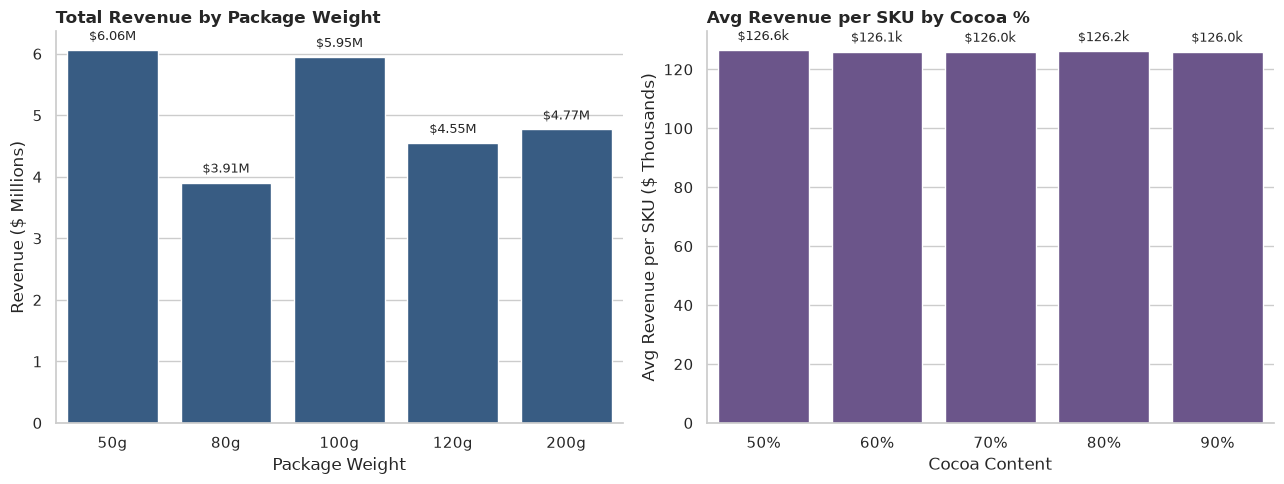

In [20]:
# Visualization: Revenue by Product Weight and Cocoa Tier
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# Weight Revenue
w_plot = weight_analysis.copy()
w_plot['weight_label'] = w_plot['weight_g'].astype(int).astype(str) + 'g'
w_plot['rev_m'] = w_plot['total_revenue'] / 1e6

sns.barplot(data=w_plot, x='weight_label', y='rev_m', color='#2b5c8f', ax=ax1)
for container in ax1.containers:
    ax1.bar_label(container, fmt='$%.2fM', padding=5, fontsize=9)
ax1.set_title('Total Revenue by Package Weight', fontsize=12, weight='bold', loc='left')
ax1.set_xlabel('Package Weight')
ax1.set_ylabel('Revenue ($ Millions)')

# Cocoa Percentage Avg Revenue per SKU
c_plot = cocoa_analysis.copy()
c_plot['cocoa_label'] = c_plot['cocoa_percent'].astype(int).astype(str) + '%'
c_plot['avg_rev_k'] = c_plot['avg_revenue_per_product'] / 1000

sns.barplot(data=c_plot, x='cocoa_label', y='avg_rev_k', color='#6a4c93', ax=ax2)
for container in ax2.containers:
    ax2.bar_label(container, fmt='$%.1fk', padding=5, fontsize=9)
ax2.set_title('Avg Revenue per SKU by Cocoa %', fontsize=12, weight='bold', loc='left')
ax2.set_xlabel('Cocoa Content')
ax2.set_ylabel('Avg Revenue per SKU ($ Thousands)')

sns.despine(top=True, right=True)
plt.tight_layout()
plt.show()


### Analytical Takeaway — Attributes
- **Weight Consistency:** Revenue is highest in 50g ($6.06M) and 100g ($5.95M) tiers due to higher SKU counts (48 and 47 SKUs respectively), but average revenue per SKU stays remarkably constant across all package sizes (~$125.5k–$126.5k).
- **Cocoa Neutrality:** Average revenue per SKU is uniform across all cocoa concentration tiers (50%, 60%, 70%, 80%, 90%), hovering near ~$126k/SKU.


## 6. Customer Demographics & Loyalty Segmentation
We link customer profiles to order history to evaluate spending behavior across age cohorts, genders, and loyalty program members.


In [21]:
# Segment customers into standardized age cohorts
age_bins = [17, 25, 35, 45, 55, 70]
age_labels = ['18-25', '26-35', '36-45', '46-55', '56-70']
df_customers['age_group'] = pd.cut(df_customers['age'], bins=age_bins, labels=age_labels)

# Merge customer demographics with sales transactions
sales_customer_merged = df_sales[['order_id', 'customer_id', 'quantity', 'revenue', 'profit']].merge(
    df_customers[['customer_id', 'age_group', 'gender', 'loyalty_member']],
    on='customer_id',
    how='left'
)

# 6.1 Age Cohort Analysis
age_performance = (
    sales_customer_merged
    .groupby('age_group')
    .agg(
        customer_count=('customer_id', 'nunique'),
        total_orders=('order_id', 'nunique'),
        total_quantity=('quantity', 'sum'),
        total_revenue=('revenue', 'sum'),
        total_profit=('profit', 'sum')
    )
    .reset_index()
)

age_performance['revenue_per_customer'] = age_performance['total_revenue'] / age_performance['customer_count']
age_performance['revenue_per_order'] = age_performance['total_revenue'] / age_performance['total_orders']
age_performance['pct_total_revenue'] = (age_performance['total_revenue'] / total_revenue) * 100

print("Age Cohort Performance:")
display(age_performance.round(2))


Age Cohort Performance:


,age_group,customer_count,total_orders,total_quantity,total_revenue,total_profit,revenue_per_customer,revenue_per_order,pct_total_revenue
0,18-25,7635,152419,457516,3884290.46,1552629.42,508.75,25.48,15.24
1,26-35,9275,185700,556915,4733427.26,1894800.96,510.34,25.49,18.57
2,36-45,9452,188389,564928,4805659.13,1922157.72,508.43,25.51,18.86
3,46-55,9378,187550,562285,4776723.79,1910728.04,509.35,25.47,18.74
4,56-70,14260,285942,857945,7286028.22,2914248.49,510.94,25.48,28.59


In [22]:
# 6.2 Gender & Loyalty Program Analysis
gender_perf = sales_customer_merged.groupby('gender').agg(
    customer_count=('customer_id', 'nunique'),
    total_orders=('order_id', 'nunique'),
    total_revenue=('revenue', 'sum'),
    total_profit=('profit', 'sum')
).reset_index()
gender_perf['rev_per_customer'] = gender_perf['total_revenue'] / gender_perf['customer_count']
gender_perf['aov'] = gender_perf['total_revenue'] / gender_perf['total_orders']

loyalty_perf = sales_customer_merged.groupby('loyalty_member').agg(
    customer_count=('customer_id', 'nunique'),
    total_orders=('order_id', 'nunique'),
    total_revenue=('revenue', 'sum'),
    total_profit=('profit', 'sum')
).reset_index()
loyalty_perf['loyalty_status'] = loyalty_perf['loyalty_member'].map({1: 'Loyalty Member', 0: 'Non-Member'})
loyalty_perf['rev_per_customer'] = loyalty_perf['total_revenue'] / loyalty_perf['customer_count']
loyalty_perf['rev_per_order'] = loyalty_perf['total_revenue'] / loyalty_perf['total_orders']

print("Gender Performance:")
display(gender_perf.round(2))
print("\nLoyalty Program Performance:")
display(loyalty_perf[['loyalty_status', 'customer_count', 'total_orders', 'total_revenue', 'rev_per_customer', 'rev_per_order']].round(2))


Gender Performance:


,gender,customer_count,total_orders,total_revenue,total_profit,rev_per_customer,aov
0,Female,24758,495689,12630103.60,5053023.43,510.14,25.48
1,Male,25242,504311,12856025.26,5141541.20,509.31,25.49



Loyalty Program Performance:


,loyalty_status,customer_count,total_orders,total_revenue,rev_per_customer,rev_per_order
0,Non-Member,24896,498102,12713088.39,510.65,25.52
1,Loyalty Member,25104,501898,12773040.47,508.80,25.45


### Analytical Takeaway — Customer Demographics
- **Demographic Split:** The registered customer base is split 50.5% Male and 49.5% Female, with nearly identical average order values ($25.49 vs $25.48) and spend per customer ($509.31 vs $510.14).
- **Loyalty Program Observations:** In this dataset, recorded loyalty members and non-members exhibit near-identical order values ($25.45 vs $25.52) and 2-year spend ($508.80 vs $510.65). Rather than asserting that loyalty programs in general are ineffective, we note that in this particular synthetic dataset, membership status does not correlate with basket expansion.


## 7. Store Channel & Geographic Performance
We analyze the 100 store locations across store formats and geographic markets.


In [23]:
# Merge sales with store metadata
sales_store_merged = df_sales[['order_id', 'store_id', 'quantity', 'revenue', 'profit']].merge(
    df_stores,
    on='store_id',
    how='left'
)

# 7.1 Store Type Performance
store_type_perf = (
    sales_store_merged
    .groupby('store_type')
    .agg(
        store_count=('store_id', 'nunique'),
        total_orders=('order_id', 'nunique'),
        total_quantity=('quantity', 'sum'),
        total_revenue=('revenue', 'sum'),
        total_profit=('profit', 'sum')
    )
    .reset_index()
)

store_type_perf['revenue_per_store'] = store_type_perf['total_revenue'] / store_type_perf['store_count']
store_type_perf['profit_per_store'] = store_type_perf['total_profit'] / store_type_perf['store_count']
store_type_perf['profit_margin_pct'] = (store_type_perf['total_profit'] / store_type_perf['total_revenue']) * 100

print("Store Format Performance:")
display(store_type_perf.sort_values('total_revenue', ascending=False).round(2))


Store Format Performance:


,store_type,store_count,total_orders,total_quantity,total_revenue,total_profit,revenue_per_store,profit_per_store,profit_margin_pct
0,Airport,30,299119,896417,7613875.92,3046173.74,253795.86,101539.12,40.01
1,Mall,26,260061,780511,6628228.67,2650844.14,254931.87,101955.54,39.99
2,Online,25,250332,751100,6386035.76,2554237.38,255441.43,102169.50,40.00
3,Retail,19,190488,571561,4857988.51,1943309.37,255683.61,102279.44,40.00


In [24]:
# 7.2 City-Level Performance (Reported Store City)
city_perf = (
    sales_store_merged
    .groupby('city')
    .agg(
        store_count=('store_id', 'nunique'),
        total_orders=('order_id', 'nunique'),
        total_revenue=('revenue', 'sum'),
        total_profit=('profit', 'sum')
    )
    .reset_index()
    .sort_values('total_revenue', ascending=False)
)
city_perf['revenue_per_store'] = city_perf['total_revenue'] / city_perf['store_count']

print("City Performance Summary:")
display(city_perf.round(2))


City Performance Summary:


,city,store_count,total_orders,total_revenue,total_profit,revenue_per_store
6,Toronto,18,180181,4593793.59,1837196.54,255210.76
1,London,16,159353,4059812.16,1622726.00,253738.26
4,Paris,16,159556,4049366.83,1620456.75,253085.43
3,New York,15,150532,3842643.97,1536934.11,256176.26
5,Sydney,13,130293,3323056.03,1330093.63,255619.69
2,Melbourne,12,119858,3058545.49,1223010.20,254878.79
0,Berlin,10,100227,2558910.79,1024147.40,255891.08


## 8. Seasonality & Holiday Impact Analysis
We examine intra-week seasonality and evaluate whether sales surge during peak holiday windows (Christmas and Thanksgiving) using average daily revenue.


In [25]:
# 8.1 Day of Week Analysis
df_sales['day_of_week'] = df_sales['order_date'].dt.day_name()
weekday_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

weekday_perf = (
    df_sales
    .groupby('day_of_week')
    .agg(
        total_days=('order_date', 'nunique'),
        total_orders=('order_id', 'nunique'),
        total_quantity=('quantity', 'sum'),
        total_revenue=('revenue', 'sum'),
        total_profit=('profit', 'sum')
    )
    .reindex(weekday_order)
    .reset_index()
)

weekday_perf['avg_daily_revenue'] = weekday_perf['total_revenue'] / weekday_perf['total_days']
weekday_perf['avg_daily_orders'] = weekday_perf['total_orders'] / weekday_perf['total_days']
weekday_perf['avg_daily_profit'] = weekday_perf['total_profit'] / weekday_perf['total_days']

print("Day of Week Performance:")
display(weekday_perf[['day_of_week', 'total_days', 'avg_daily_revenue', 'avg_daily_orders', 'avg_daily_profit']].round(2))


Day of Week Performance:


,day_of_week,total_days,avg_daily_revenue,avg_daily_orders,avg_daily_profit
0,Monday,105,34806.14,1365.02,13913.68
1,Tuesday,105,34982.97,1371.10,13995.37
2,Wednesday,104,34810.76,1364.42,13919.42
3,Thursday,104,34788.94,1366.19,13922.84
4,Friday,104,34901.55,1368.11,13959.66
5,Saturday,104,34944.97,1372.51,13978.17
6,Sunday,105,34817.76,1368.56,13933.19


In [26]:
# 8.2 Holiday Window Definition & Comparison
daily_sales = (
    df_sales
    .groupby('order_date')
    .agg(
        total_revenue=('revenue', 'sum'),
        total_profit=('profit', 'sum'),
        total_orders=('order_id', 'nunique'),
        total_quantity=('quantity', 'sum')
    )
    .reset_index()
)

daily_sales['year'] = daily_sales['order_date'].dt.year
daily_sales['period'] = 'Regular Days'

# Christmas window: Dec 20 to Dec 26 (7 days each year)
for yr in [2023, 2024]:
    xmas_mask = daily_sales['order_date'].between(f'{yr}-12-20', f'{yr}-12-26')
    daily_sales.loc[xmas_mask, 'period'] = 'Christmas Window'

# Thanksgiving window: 7-day window centered on US Thanksgiving (date ± 3 days)
# 2023 Thanksgiving: Nov 23 -> Nov 20 to Nov 26
# 2024 Thanksgiving: Nov 28 -> Nov 25 to Dec 01
daily_sales.loc[daily_sales['order_date'].between('2023-11-20', '2023-11-26'), 'period'] = 'Thanksgiving Window'
daily_sales.loc[daily_sales['order_date'].between('2024-11-25', '2024-12-01'), 'period'] = 'Thanksgiving Window'

holiday_comparison = (
    daily_sales
    .groupby('period')
    .agg(
        day_count=('order_date', 'nunique'),
        avg_daily_revenue=('total_revenue', 'mean'),
        avg_daily_profit=('total_profit', 'mean'),
        avg_daily_orders=('total_orders', 'mean'),
        avg_daily_quantity=('total_quantity', 'mean')
    )
    .reindex(['Regular Days', 'Christmas Window', 'Thanksgiving Window'])
    .reset_index()
)

print("Holiday vs Regular Days Comparison (Daily Averages):")
display(holiday_comparison.round(2))


Holiday vs Regular Days Comparison (Daily Averages):


,period,day_count,avg_daily_revenue,avg_daily_profit,avg_daily_orders,avg_daily_quantity
0,Regular Days,703,34879.50,13951.44,1368.55,4104.95
1,Christmas Window,14,34643.59,13883.60,1353.79,4080.57
2,Thanksgiving Window,14,34345.21,13737.90,1354.00,4048.64


C:\Users\Devendra\AppData\Local\Temp\ipykernel_13868\2980279636.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(
findfont: Failed to find font weight medium for DejaVu Sans, now using 400.


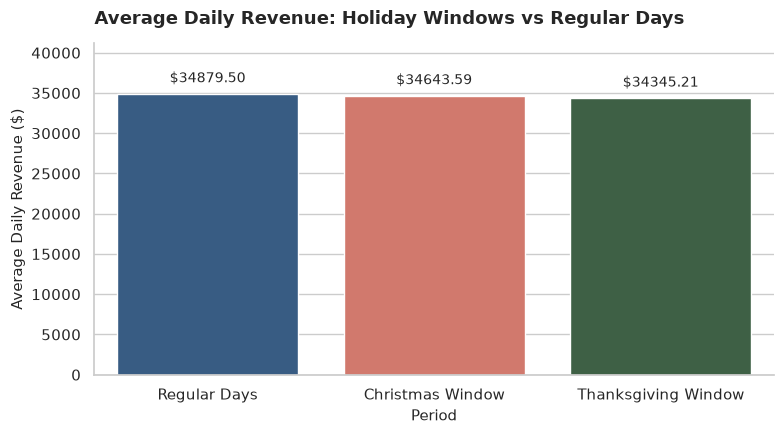

In [27]:
# Visualizing Holiday vs Regular Day Performance
plt.figure(figsize=(8, 4.5))
ax = sns.barplot(
    data=holiday_comparison,
    x='period',
    y='avg_daily_revenue',
    palette=['#2b5c8f', '#e26d5c', '#386641']
)

for container in ax.containers:
    ax.bar_label(container, fmt='$%.2f', padding=6, fontsize=10, weight='medium')

ax.set_title('Average Daily Revenue: Holiday Windows vs Regular Days', fontsize=13, weight='bold', pad=14, loc='left')
ax.set_ylabel('Average Daily Revenue ($)', fontsize=11)
ax.set_xlabel('Period', fontsize=11)
ax.set_ylim(0, holiday_comparison['avg_daily_revenue'].max() * 1.18)
sns.despine(top=True, right=True)
plt.tight_layout()
plt.show()


## 9. Comprehensive Synthesis & Analytical Limitations

### Key Business Insights
1. **Financial Scale:** Generated **$25,486,128.86** in gross revenue and **$10,194,564.63** in operating profit across 1,000,000 transactions, delivering a portfolio profit margin of **40.00%**.
2. **Brand & Catalog Stability:** Confectionery brands contribute with near-uniform velocity, each generating approximately $3.5M–$4.7M over the two-year period.
3. **Channel Productivity:** While Airport (30 stores) and Mall (26 stores) account for the largest retail presence, all four channels demonstrate identical per-store productivity (~$254K–$256K revenue per store over 2 years).

### Data Quality & Methodological Limitations
1. **Synthetic Generation Patterns:**
   - Intra-week variation is less than **0.6%** ($34,788.94 to $34,982.97 per day).
   - Holiday windows show no statistically significant uplift over regular operating days.
   - Demographics display near-perfect 50/50 splits with negligible spending divergence.
2. **Catalog Integrity (Unmatched Keys):**
   - 9,764 transaction records reference non-existent product keys `P0000` and `P0201`.
3. **Geographic Incoherence:**
   - 80% of stores possess discordant city-country pairs due to randomized attribute generation.
4. **Causality vs. Description:**
   - All findings in this study reflect descriptive patterns within synthetic transaction records and should not be used to infer causal consumer behaviors in live retail operations.
